## CA1 MACHINE LEARNING

Student name: Jhenifer Damasceno Damiski Student number: 2026195 Course: Higher Diploma in Data Analytics

## Introdution

Bicycle-sharing schemes are an alternative form of urban transport that can make it easier for people to get around cities. However, the number of bicycles rented can vary depending on factors such as the time of day, weather conditions and the calendar. Understanding these variations can help to identify patterns in bicycle usage and improve the management of bike-sharing services (Eren and Uz, 2020).

The following assignment will focus on the Transport domain and will use the ‘Seoul Bike Sharing Demand’ dataset to analyse demand for bike hire. The study combines exploratory data analysis, clustering and time series forecasting to better understand patterns in hourly bike hire and how demand changes over the course of a year.
The focus of this study is the variation in demand for bicycle hire over time. The dataset contains information on hourly hire rates, alongside weather and calendar variables, providing an opportunity to investigate how different observations can be clustered according to their characteristics and how demand for hire changes over time.

The analysis will consider two perspectives: identifying patterns in the observations using clustering techniques and investigating the behaviour of demand for bike hire as a time series.

## TASK I

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('SeoulBikeData.csv')

In [3]:
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


Looking at the firts five rows of the dataset provides an initial understanding of the information available for each hour. The dataset includes the number of weather and calendar conditions. The main variable being analysed is "Rented Bike Count", which represents the number of bicycles rented. Other variables, such as "Hour", "Temperature(°C)", "Humidity(%)", "Wind speed(m/s)", "Rainfall(mm)", "Snowfall(cm)", "Seasons", "Holiday" and "Functioning Day", can help explain how demand changes under different conditions.
From this initial inspection, it is possible to see that the dataset contains both numerical and categorical variables. These variables provide useful factors that may influence bike usage in the transport sector.

In [4]:
df.shape

(8760, 14)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   object 
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   object 
 12  Holiday                    8760 non-null   object 
 13  Functioning Day            8760 non-null   objec

The dataset above contains 8,760 observations and 14 variables, with no missing values identified by the df.info() function. 
It includes numerical and categorical variables relating to bicycle hire, the weather and calendar conditions. The "Date" column is stored as an object and needs to be converted to a date format for time series analysis.

In [6]:
df.isnull().sum()

Date                         0
Rented Bike Count            0
Hour                         0
Temperature(°C)              0
Humidity(%)                  0
Wind speed (m/s)             0
Visibility (10m)             0
Dew point temperature(°C)    0
Solar Radiation (MJ/m2)      0
Rainfall(mm)                 0
Snowfall (cm)                0
Seasons                      0
Holiday                      0
Functioning Day              0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

The initial data quality checks found no missing values or duplicated records in the dataset.
Therefore, no rows needed to be removed, and the complete dataset was retained for the next stages of the analysis.

In [8]:
df.describe()

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm)
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000


The descriptive statistics help to understand the numerical variables in the dataset and show how the values are distributed.
The "Rental Bike Count" has a mean of approximately 704.60 and a median of 504.50. The minimum value is zero, while the maximum is 3,556. Since the mean is higher than the median, this suggests that the distribution is not symmetrical, with some higher rental counts increasing the average.
The "Hour" variable ranges from 0 to 23, covering all hours of the day. Temperature varies from -17.8°C to 39.4°C, while humidity ranges from 0% to 98%.
The weather variables also show variation across the dataset. Wind speed ranges from 0 to 7.4m/s, rainfall from 0 to 35mm, and snowfall from 0 to 8.8cm.
These results give an initial overview of the data and help to understand the differences in rental demand and weather conditions before moving on the visual analysis.

In [9]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       8760 non-null   datetime64[ns]
 1   Rented Bike Count          8760 non-null   int64         
 2   Hour                       8760 non-null   int64         
 3   Temperature(°C)            8760 non-null   float64       
 4   Humidity(%)                8760 non-null   int64         
 5   Wind speed (m/s)           8760 non-null   float64       
 6   Visibility (10m)           8760 non-null   int64         
 7   Dew point temperature(°C)  8760 non-null   float64       
 8   Solar Radiation (MJ/m2)    8760 non-null   float64       
 9   Rainfall(mm)               8760 non-null   float64       
 10  Snowfall (cm)              8760 non-null   float64       
 11  Seasons                    8760 non-null   object        
 12  Holida

The "Date" column was initially stored as an object and was converted to the datetime format using pd.to_datetime(). The df.info() output confirms that the data type is now datetime64[ns], allowing the dates to be used for time series analysis and to investigate changes in bike rental demand over time.

In [11]:
df["Seasons"].unique()

array(['Winter', 'Spring', 'Summer', 'Autumn'], dtype=object)

In [12]:
df["Holiday"].unique()

array(['No Holiday', 'Holiday'], dtype=object)

In [13]:
df["Functioning Day"].unique()

array(['Yes', 'No'], dtype=object)

The dataset contains three categorical variables: "Seasons", with four categories ("Winter, Spring, Summer and Autumn"), and "Holiday" and "Functioning Day", which each have two categories. These variables help explore whether bike rental demand changes depending on the season, holidays or whether the service is operating on a particular day.

In [14]:
df[['Hour', 'Humidity(%)', 'Rainfall(mm)', 'Snowfall (cm)', 'Wind speed (m/s)']].min()

Hour                0.0
Humidity(%)         0.0
Rainfall(mm)        0.0
Snowfall (cm)       0.0
Wind speed (m/s)    0.0
dtype: float64

In [15]:
df[['Hour', 'Humidity(%)', 'Rainfall(mm)', 'Snowfall (cm)', 'Wind speed (m/s)']].max()

Hour                23.0
Humidity(%)         98.0
Rainfall(mm)        35.0
Snowfall (cm)        8.8
Wind speed (m/s)     7.4
dtype: float64

As noted above, the ranges of the variables were checked to understand the values in the dataset. The "Hour" variable covers all hours from 0 to 23, whilst humidity ranges from 0% to 98%. Precipitation ranges from 0 to 35 mm, snowfall from 0 to 8.8 cm and wind speed from 0 to 7.4 m/s.
These ranges demonstrate the variety of weather conditions and times of day represented in the dataset, with no immediate issues having been identified.

In [16]:
df["Date"].min()

Timestamp('2017-12-01 00:00:00')

In [17]:
df["Date"].max()

Timestamp('2018-11-30 00:00:00')

In [18]:
df["Date"].nunique()

365

The dataset covers the period from 1 December 2017 to 30 November 2018, with 365 unique dates. It contains hourly observations throughout the year, making it suitable for analysing changes in bike rental demand over time.

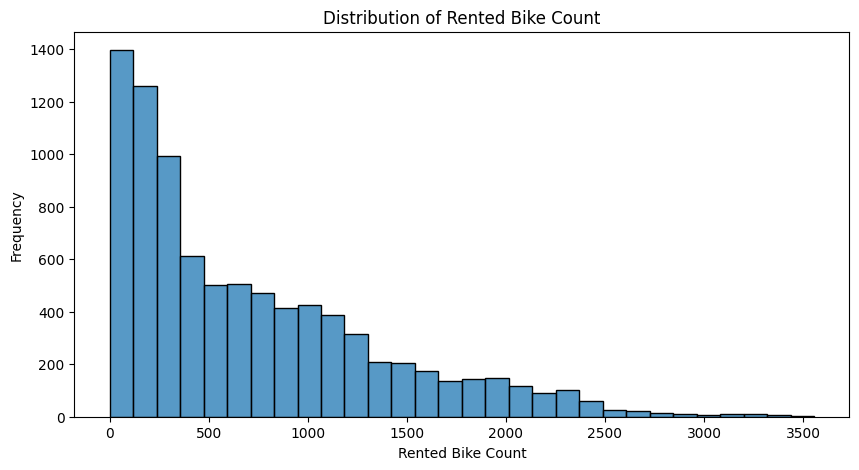

In [19]:
plt.figure(figsize=(10, 5))
sns.histplot(df["Rented Bike Count"], bins=30)
plt.title("Distribution of Rented Bike Count")
plt.xlabel("Rented Bike Count")
plt.ylabel("Frequency")
plt.show()

The graph above shows that the majority of hourly observations have relatively low rental counts, whilst a smaller number of observations have much higher values. This indicates a positively skewed distribution, with a long tail towards the higher rental counts.
This is consistent with the fact that the mean (704.60) is higher than the median (504.50), suggesting that rental demand varies considerably across the dataset. These differences will be explored in greater depth in the time-series analysis and data clustering.

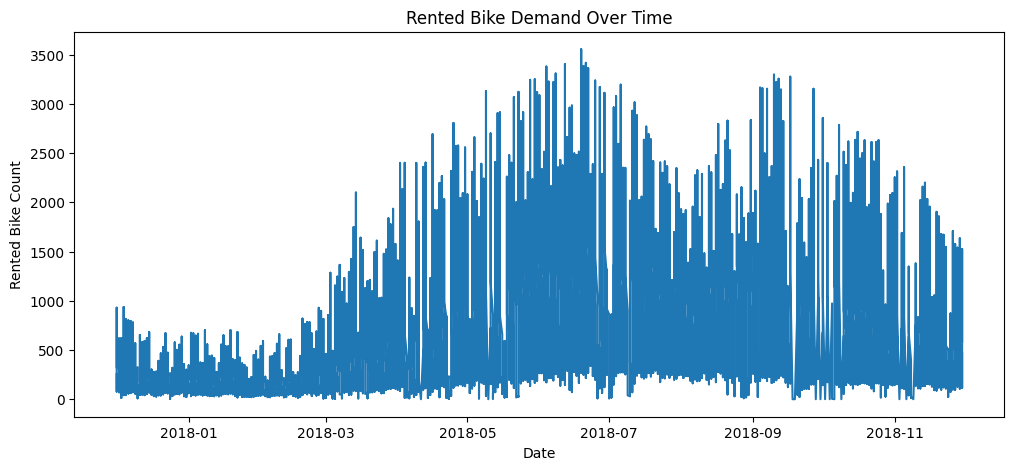

In [20]:
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Rented Bike Count"])
plt.title("Rented Bike Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Rented Bike Count")
plt.show()

The ‘Rented Bike Demand Over Time’ chart, on the other hand, shows that demand for bike hire varies throughout the year, with generally fewer hires during the winter and higher demand in spring and summer. Demand appears to decline again towards the end of the year.
However, the chart is difficult to interpret because it includes 24 observations per day. Subsequently, the date and time will be combined into a single timestamp to make it easier to identify trends, seasonal patterns and possible anomalies.

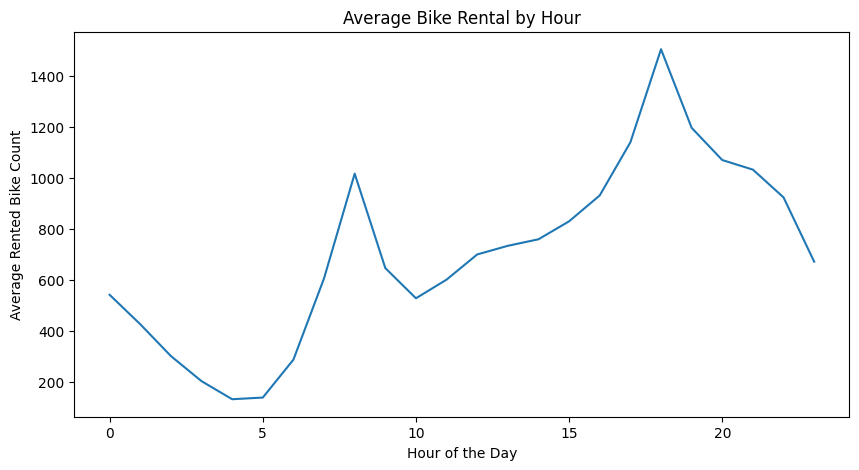

In [21]:
hourly_demand = df.groupby("Hour")["Rented Bike Count"].mean()

hourly_demand.plot(kind="line", figsize=(10, 5))
plt.title("Average Bike Rental by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Rented Bike Count")
plt.show()

The average number of rented bicycles changes throughout the day. Demand is lowest around 04:00–05:00, then increases to a morning peak of approximately 1,020 rentals at 08:00.
After decreasing, demand rises again during the afternoon, reaching its highest point at around 18:00, with approximately 1,500 rentals. It then gradually decreases towards the end of the day.
These two peaks show that bike rental demand is not evenly distributed throughout the day. This hourly pattern will be useful for the following clustering and time series analysis.

## TASK II

In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [23]:
clustering_data = df[[
    "Rented Bike Count",
    "Hour",
    "Temperature(°C)",
    "Humidity(%)",
    "Wind speed (m/s)",
    "Visibility (10m)",
    "Dew point temperature(°C)",
    "Solar Radiation (MJ/m2)",
    "Rainfall(mm)",
    "Snowfall (cm)"
]].copy()

In [24]:
clustering_data.head()

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm)
0,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0
1,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0
2,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0
3,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0
4,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0


In [25]:
clustering_data.shape

(8760, 10)

The dataset for clustering contains 8,760 observation and 10 numerical variables. These include Rented Bike Count, Hour and several weather-related variables, such as temperature, humidity, wind speed, visibility, rainfall and snowfall. The variables shown in the table above were selected because they provide information on the demand for bicycle hire and the weather conditions for each observation. the aim is to identify groups of observations that share similar characteristics.

In [26]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(clustering_data)

In [27]:
scaled_data[:5]

array([[-0.69865046, -1.66132477, -1.51395724, -1.04248288,  0.45847578,
         0.92587135, -1.65960467, -0.65513172, -0.13179988, -0.17189109],
       [-0.77617457, -1.51686175, -1.53907415, -0.99336999, -0.8925615 ,
         0.92587135, -1.65960467, -0.65513172, -0.13179988, -0.17189109],
       [-0.82423951, -1.37239873, -1.58093567, -0.94425709, -0.69955617,
         0.92587135, -1.66726186, -0.65513172, -0.13179988, -0.17189109],
       [-0.92657134, -1.2279357 , -1.59768028, -0.8951442 , -0.79605883,
         0.92587135, -1.65960467, -0.65513172, -0.13179988, -0.17189109],
       [-0.97153532, -1.08347268, -1.58093567, -1.09159578,  0.55497844,
         0.92587135, -1.73617656, -0.65513172, -0.13179988, -0.17189109]])

In scaled_data[:5], we can see that the selected variables were standardised before the clustering algorithms were applied, as they use different measurement scales. The StandardScaler adjusts the variables so that thay have a mean of zero and a standard deviation of one. This ensures that variables with langer values do not exert greater influence on the clustering results simply because of their scale(Scikit-learn Developers, 2026)

In [28]:
from sklearn.cluster import KMeans
Kmeans = KMeans(n_clusters=3, random_state=42)
Kmeans_labels = Kmeans.fit_predict(scaled_data)
Kmeans_labels[:10]

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2], dtype=int32)

In [29]:
silhouette_Kmeans = silhouette_score(scaled_data,Kmeans_labels)
davies_Kmeans = davies_bouldin_score(scaled_data, Kmeans_labels)

print("K-Means Silhouette Score:", silhouette_Kmeans)
print("K-Means Davies-Bouldin Index:", davies_Kmeans)

K-Means Silhouette Score: 0.2292339634804752
K-Means Davies-Bouldin Index: 1.5132755495985961


The K-Means algorithm was applied using three clusters, achieving a Silhouette Score of 0.2292 and a Davies-Bouldin index of 1.5132. These results suggest that the clusters show some separation, but there is also overlap between them. The low Silhouette Score indicates that the observations are not clearly separated into distinct groups, as values closer to zero suggest greater overlap (Scikit-learn Developers, 2026).
The Davies-Bouldin index supports this interpretation, as lower values indicate more clearly defined clusters, with zero being the best possible value (Scikit-learn Developers, 2026).

In [30]:
agglomerative = AgglomerativeClustering(n_clusters=3)

agglomerative_labels = agglomerative.fit_predict(scaled_data)

agglomerative_labels[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [31]:
silhouette_Agglomerative = silhouette_score(scaled_data, agglomerative_labels)
davies_Agglomerative = davies_bouldin_score(scaled_data, agglomerative_labels)

print("Agglomerative Silhouette Score:", silhouette_Agglomerative)
print("Agglomerative Davies-Bouldin Index:", davies_Agglomerative)

Agglomerative Silhouette Score: 0.19975413404030704
Agglomerative Davies-Bouldin Index: 1.6669087133129217


In the results above, agglomerative clustering was also applied using three clusters, achieving a Silhouette Score of 0.1997 and a Davies-Bouldin Index of 1.6669. Compared to K-Means, the results show that agglomerative clustering produced less clearly separated clusters, with a lower Silhouette Score and a higher Davies-Bouldin Index.
This algorithm uses a hierarchical approach, in which individual observations or smaller clusters are progressively merged based on their similarity(Scikit-learn developers, 2026).

In [32]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

pca_data = pca.fit_transform(scaled_data)

pca_data[:5]

array([[-1.88475074, -2.06166786],
       [-2.1598159 , -1.64245803],
       [-2.13776281, -1.71856594],
       [-2.17977025, -1.68811775],
       [-1.8837918 , -2.27827436]])

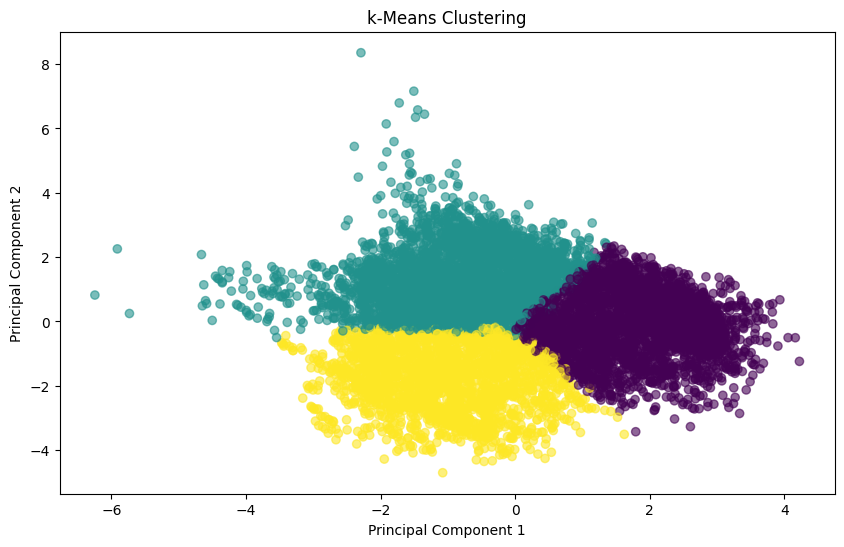

In [33]:
plt.figure(figsize=(10, 6))

plt.scatter(
    pca_data[:, 0],
    pca_data[:, 1],
    c=Kmeans_labels,
    cmap="viridis",
    alpha=0.6
)
plt.title("k-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

Looking at the PCA plot with K-Means above, we can identify three cluters in different areas of the plot. The yellow cluster is on the right-hand side, the green is concentrated in the lower and central areas, and the purple cluster is on the left hand and upper sides. This suggests that the observations in each cluster exhibit some differences across the ten standardised variables used in the analysis.
However, in the plot, the clusters are not completely separated, particularly near the centre, where there is some overlap. This is also reflected in the Silhouette index of 0.2292, which suggests that the separation between the clusters is relatively weak. The Davies-Bouldin Index of 1.5132 supports this interpretation.
Overall, K-Means was able to identify three groups in the dataset, but the graph and the evaluation scores show that some observations still have similar characteristics, making the clusters less clearly defined.

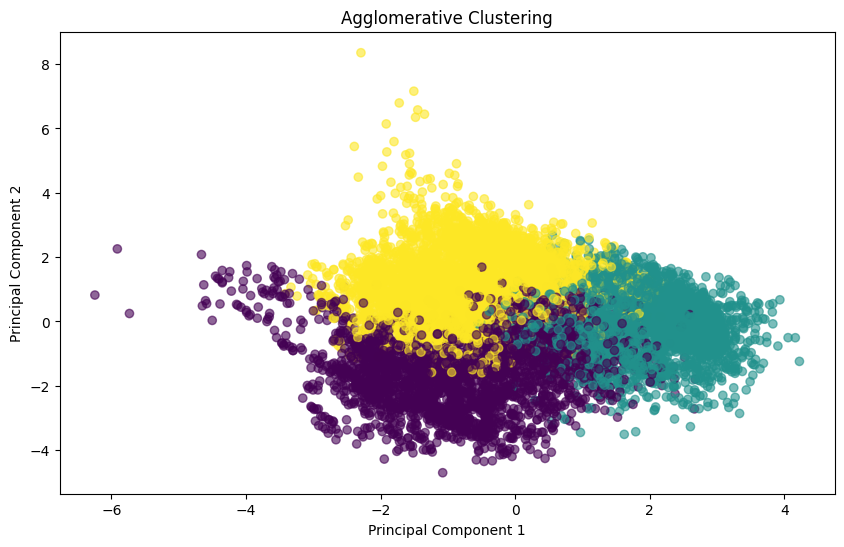

In [34]:
plt.figure(figsize=(10, 6))

plt.scatter(
    pca_data[:, 0],
    pca_data[:, 1],
    c=agglomerative_labels,
    cmap="viridis",
    alpha=0.6
)
plt.title("Agglomerative Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

For the PCA plot of the agglomerative clustering above, we can also identified three clusters, but the colours overlap more, particularly in the central area of the plot. The observations also appear more scattered across the plot, which makes it difficult to distinguish the boudaries between the clusters compared to K-Means. The evaluation indices reflect what we can observe in the plot. Agglomerative clustering achieved a Silhouette Score of 0.1997, which is lower than the 0.2292 obtained by the K-Means method. Its Davies-Bouldin index was 1.6669, compared with 1.5132 for K-Means. These results suggest that the clusters identified by agglomerative clustering are less clearly separated.
Based on both the graphs and the evaluation scores, K-Means performed slightly better at separating the observations into three clusters using the selected variables.

In [35]:
print("K-Means cluster sizes:")
print(pd.Series(Kmeans_labels).value_counts().sort_index())

print("\nAgglomerative cluster sizes:")
print(pd.Series(agglomerative_labels).value_counts().sort_index())

K-Means cluster sizes:
0    3001
1    3465
2    2294
Name: count, dtype: int64

Agglomerative cluster sizes:
0    2727
1    2440
2    3593
Name: count, dtype: int64


For this analysis, I selected K-Means and Agglomerative Clustering to compare two different ways of grouping the observations. K-Means was chosen because it groups the data into a predefined number of clusters, while Agglomerative Clustering follows a hierarchical approach, gradually grouping observations based on their similarities. By using both algorithms, it is possible to compare their results and see which one produces better-defined clusters for the selected variables (Scikit-learn Developers, 2026).

The cluster sizes differed between the two algorithms. K-Means produced clusters with 3,001, 3,465 and 2,294 observations, whilst Agglomerative Clustering produced clusters with 2,727, 2,440 and 3,593 observations.
Overall, K-Means performed better in this analysis. It achieved a higher Silhouette Score (0.2292) than agglomerative clustering 
(0.1997) and a lower Davies-Bouldin Index (1.5132 compared with 1.6669). In the PCA plots above, we can see that the K-Means clusters appear slightly more separated, whilst agglomerative clustering shows more overlap between the groups.
Based on the cluster sizes, the evaluation scores and the plots, K-Means was the best choice for this dataset. However, both algorithms showed some overlap between the clusters, therefore, the groups should not be considered completely distinct.

## TASK III

In [36]:
df = df.reset_index(drop=True)

df["Datetime"] = df["Date"] + pd.to_timedelta(df["Hour"], unit="h")

df = df.sort_values("Datetime")

df = df.set_index("Datetime")

df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
Datetime,,,,,,,,,,,,,,
2017-12-01 00:00:00,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2017-12-01 01:00:00,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2017-12-01 02:00:00,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
2017-12-01 03:00:00,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2017-12-01 04:00:00,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


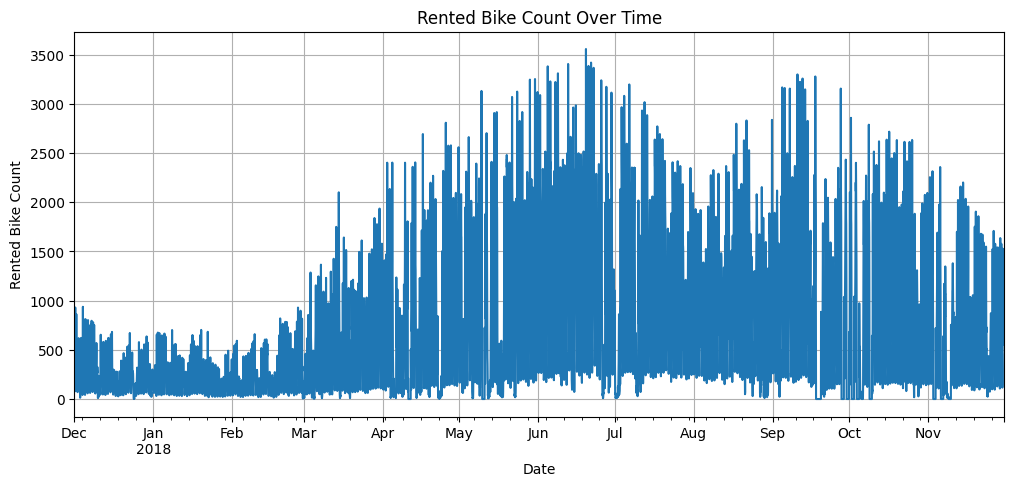

In [37]:
plt.figure(figsize=(12, 5))

df["Rented Bike Count"].plot()

plt.title("Rented Bike Count Over Time")
plt.xlabel("Date")
plt.ylabel("Rented Bike Count")
plt.grid(True)
plt.show()

The dataset was prepared using data for time series analysis. I combined the "Date" and "Hour" columns into a single "Datetime" variable. I then sorted the observations by hour and used "Datetime" as the index. This allowes me to work with the data in chonological order, which is importante when analysing the demand for hourly bike hire. The dataset covers one year, from December 2017 to November 2018, with 8,760 hourly obervations. Looking at the chart above, I noticed that the number of bicycles rented varies considerably throughout the year. The number of rentals is generally lower during the winter, whilst higher figures can be observed during spring and summer. There are also several fluctuations within the same period.
These variations are worth examining in more detail before selecting a forecasting model. Although the graf gives an ideia of how demand varies over time, it cannot indicate whether the data is stationary, no which ARIMA parameters would be appropriate. In the next steps, we will analyse stationarity and autocorrelation before moving on to model selection.

In [38]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(df["Rented Bike Count"])

print(f"ADF Statistic: {adf_result[0]}")
print(f"p-value: {adf_result[1]}")

ADF Statistic: -6.94697088797581
p-value: 9.914782088249435e-10


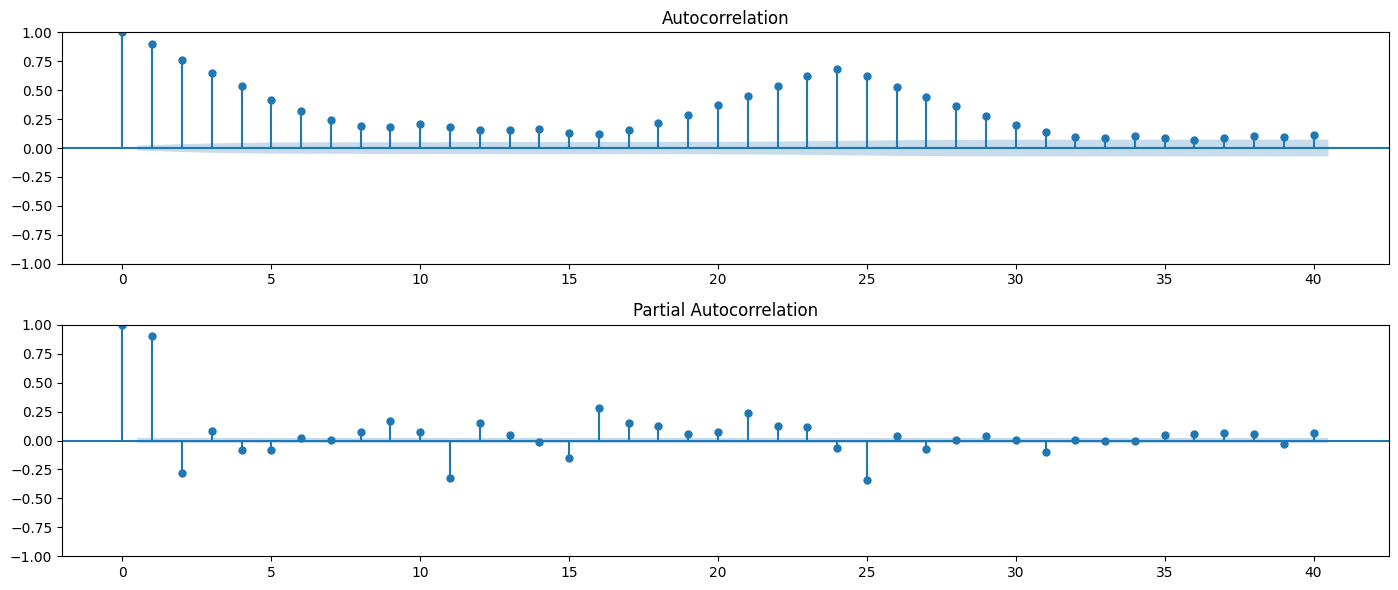

In [39]:
import statsmodels.api as sm

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(211)
sm.graphics.tsa.plot_acf(
    df["Rented Bike Count"].dropna(),
    lags=40,
    ax=ax1
)

ax2 = fig.add_subplot(212)
sm.graphics.tsa.plot_pacf(
    df["Rented Bike Count"].dropna(),
    lags=40,
    ax=ax2
)

plt.tight_layout()
plt.show()

I began by analysing time series data and used the ADF test to check whether the " Rented Bike Count" series was stationary. The test yielded an ADF value of -6.94697 and a p-value of 9.91478 × 10⁻¹⁰. The p-value is well bellow 0.05, therefore, I rejected the null hypothesis that the series has a unit root. Based on this test, the series can be treated as stationary. This means that it was not necessary to aplly differentiation to the non-seasonal part of the model, so I used d = 0.
Following this verificaction, I analysed the ACF and PACF plots to gain a better understanting of how the bicycle hire figures relate to previous observations. These plots are useful when deciding which autoregression "p" and moving average "q" values shoul be tested in an ARIMA model. In the ACF plot, the first lags show strong positive autocorrelation. The PACF also shows stronger dependence in the first lags, suggesting that observations from previous hours may be related to the current number of rentals. Another detail I noticed was the pattern around lag 24.
Because the data is recorded every hour, lag 24 represents approximately 24 hours, or one full day. This caught my attention because it could indicate that rental demand follows a daily pattern. For exemplo, the number of rented bikes may change depending on the time of day, with similar patterns occuring again on following days. However, the plots alone are not enough to confirm this, so I also considered a seasonal model with a period of 24 hours in the next stage of the analysis.
I used the ACF and PACF results as a starting point for choosing the model parameters, rather that relying on these plots to make the final decision. They helped me understant the relationships between observations at different lags, but they did not given a definite answer about which p and q values would work best. I therefore tested different ARIMA combinations and compared their AIC values. This allowes me to compare the models and choose the final non-seasonal specification based on the results.

In [42]:
from statsmodels.tsa.arima.model import ARIMA

train_size = int(len(df) * 0.8)

train = df["Rented Bike Count"].iloc[:train_size]
test = df["Rented Bike Count"].iloc[train_size:]

aicVal = []

for ari in range(0, 3):
    for maj in range(0, 3):
        try:
            arima_obj = ARIMA(
                train,
                order=(ari, 0, maj)
            )

            arima_obj_fit = arima_obj.fit()

            aicVal.append([
                ari,
                0,
                maj,
                arima_obj_fit.aic
            ])

        except ValueError:
            pass

for val in aicVal:
    print(f"ARIMA({val[0]}, {val[1]}, {val[2]}) -> AIC: {val[3]:.2f}")


C:\Users\JHENI\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
C:\Users\JHENI\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
C:\Users\JHENI\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
C:\Users\JHENI\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
C:\Users\JHENI\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self.

ARIMA(0, 0, 0) -> AIC: 110715.53
ARIMA(0, 0, 1) -> AIC: 104097.69
ARIMA(0, 0, 2) -> AIC: 100683.74
ARIMA(1, 0, 0) -> AIC: 98510.07
ARIMA(1, 0, 1) -> AIC: 97826.37
ARIMA(1, 0, 2) -> AIC: 97827.17
ARIMA(2, 0, 0) -> AIC: 97890.80
ARIMA(2, 0, 1) -> AIC: 97827.17
ARIMA(2, 0, 2) -> AIC: 97446.13


In [43]:
best_model = min(aicVal, key=lambda x: x[3])

print(f"\nMinimum AIC value: {best_model[3]:.2f}")
print(f"Best model: ARIMA({best_model[0]}, {best_model[1]}, {best_model[2]})")


Minimum AIC value: 97446.13
Best model: ARIMA(2, 0, 2)


After checking the results of the ADF test, the differentiation parameter d=0 was retained, as the test indicated that the series was stationary. I then used the ACF and PACF plots to help decide which values of "p" and "q" would be worth testing.
I carried out the test for nine different ARIMA models, using values from 0 to 2 for both "p" and "q". To compare their results, I used the AIC. This measure helps to compare models, talking into account both the degree of fit to the data and their complexity. When comparing the models tested here, a lower AIC indicates a more suitable option. Of the nine models the ARIMA 2,0,2 model had the lowest AIC, at 97,446.13. Based on this comparison, I selected it as the preferrend non-seasonal ARIMA model from among the specifications tested.
The final choice was based on the different stages of the analysis. The ADF test indicated the use of d=0, whilst the ACF nad PACF plots helped to guide the selection of the other parameters. The AIC comparison then showed that p=2 and q=2 provided the best results amongst the nine models tested.

In [44]:
from statsmodels.tsa.arima.model import ARIMA

arima_model = ARIMA(
    train,
    order=(2, 0, 2)
)

arima_fit = arima_model.fit(
    method_kwargs={"maxiter":200}
)

print(arima_fit.summary())

C:\Users\JHENI\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
C:\Users\JHENI\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
C:\Users\JHENI\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
C:\Users\JHENI\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\JHENI\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA paramete

                               SARIMAX Results                                
Dep. Variable:      Rented Bike Count   No. Observations:                 7008
Model:                 ARIMA(2, 0, 2)   Log Likelihood              -48717.064
Date:                Tue, 20 Oct 2026   AIC                          97446.127
Time:                        14:28:04   BIC                          97487.256
Sample:                    12-01-2017   HQIC                         97460.299
                         - 09-18-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        691.4924     42.044     16.447      0.000     609.087     773.897
ar.L1         -0.1557      0.007    -22.468      0.000      -0.169      -0.142
ar.L2          0.8441      0.007    121.341      0.0

In [45]:
print(arima_fit.mle_retvals)

{'fopt': np.float64(6.951635798882137), 'gopt': array([ 1.59516845e-07, -1.23334232e-05,  1.39944056e-05,  7.52722329e-06,
       -3.90558696e-06, -1.29756650e-05]), 'fcalls': 371, 'warnflag': 0, 'converged': True, 'iterations': 46}


In [46]:
#The maximum number of iterations was increased to allow the ARIMA model estimation to converge.
arima_fit = arima_model.fit(
    method_kwargs={"maxiter": 200}
)

print(arima_fit.mle_retvals)

C:\Users\JHENI\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\JHENI\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


{'fopt': np.float64(6.951635798882137), 'gopt': array([ 1.59516845e-07, -1.23334232e-05,  1.39944056e-05,  7.52722329e-06,
       -3.90558696e-06, -1.29756650e-05]), 'fcalls': 371, 'warnflag': 0, 'converged': True, 'iterations': 46}


After selecting ARIMA 2,0,2 model, I fitted the model using the 7,008 training observations. The model returned an AIC of 97,446.127, which is consistent with the value obtained during model selection. The BIC was 97,487.256, whilst the HQIC was 97,460.299. These values provided additional infromation for the evaluation of the fitted model.
The optimisation process was also successfully completed. The output shows "converged = True" after 46 iterations, which means that the estimation procedure was able to find a solution for the model parameters. However, some warnings appeared during the fitting process. One of these indicated that the date and time index did not have an explicitly "h". This corresponds to the structure of the dataset, which contains hourly observations. 
There were also warnings regarding the initial values used for the autoregressive and moving average parameters. More specifically, the initial AR values were identified as non-invertible. These warnings refer to the initial values used during optimisation and do not necessarily indicate a problem with the final fitted model. The procedure used alternative initial values and converged successfully.
Based on the models results, the warnings should still be reported, but they do not mean that the fitting process has failed. As the optimisation has converged, the model can proceed to the forecast evaluation, in which its performance will be assessed using the test data.

In [47]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_model = SARIMAX(
    train,
    order=(2, 0, 2),
    seasonal_order=(1, 0, 0, 24)
)

sarima_fit = sarima_model.fit(
    disp=False,
    maxiter=200

)

print(sarima_fit.summary())
print(sarima_fit.mle_retvals)

C:\Users\JHENI\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
C:\Users\JHENI\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


                                      SARIMAX Results                                      
Dep. Variable:                   Rented Bike Count   No. Observations:                 7008
Model:             SARIMAX(2, 0, 2)x(1, 0, [], 24)   Log Likelihood              -47235.068
Date:                             Tue, 20 Oct 2026   AIC                          94482.136
Time:                                     14:28:34   BIC                          94523.265
Sample:                                 12-01-2017   HQIC                         94496.308
                                      - 09-18-2018                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.8068      0.006    319.402      0.000       1.796       1.818
ar.L2         -0.8068      

When I looked at the ACF plot, I noticed that there was a pattern around lag 24. As each observation represents one hour, I thought it would be worth checking if the number of rented bikes followed a similar pattern every 24 hours. For this reason, I decided to try a seasonal model to see if it could better represent the changes in bike rental demand.
I used SARIMAX(2,0,2)(1,0,0,24) for this analysis. I kept the non-seasonal part 2,0,2 from the ARIMA model that I selected earlier based on the AIC results. I then added the seasonal part 1,0,0,24, which allows the model to consider the relationship between observations that are 24 hours apart. In this way, I could check whether including a daily seasonal pattern would improve the model.
After fitting the model, I obtained an AIC of 94,482.136, compared with 97,446.127 for the previous ARIMA model. The SARIMAX model therefore had a lower AIC, which suggests that it fitted the data better when the seasonal component was included. However, I understand that a lower AIC does not necessarily mean that the model will make more accurate predictions. For this reason, I still needed to compare its forecasts with the actual values in the test dataset.
Looking at the model output, I also saw that the estimation process converged successfully after 61 iterations. However, there was a warning about the covariance matrix being singular or close to singular. According to this warning, the standard errors of the estimated coefficients might not be reliable. Although the model converged, this is still a limitation to consider when interpreting the results, as successful convergence does not automatically mean that every part of the estimation is reliable.
After checking these results, I continued with the forecast evaluation. I used out-of-sample metrics, including MAE and RMSE, to compare the predicted bike rental counts with the actual values in the test dataset. This comparison was important because it allowed me to investigate whether adding the seasonal component made a real difference to the forecasting performance, rather than relying only on the AIC value.

In [48]:
train_size = int(len(df) * 0.8)

train = df["Rented Bike Count"].iloc[:train_size]
test = df["Rented Bike Count"].iloc[train_size:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 7008
Testing observations: 1752


In [49]:
forecast = arima_fit.forecast(steps=len(test))

print("Forecasted observations:", len(forecast))

Forecasted observations: 1752


The testing period contains 1,752 observations, and both models were used to generate forecasts for this same period. The ARIMA model was first used to produce the predicted values for the testing data, which were then compared with the corresponding actual observations.

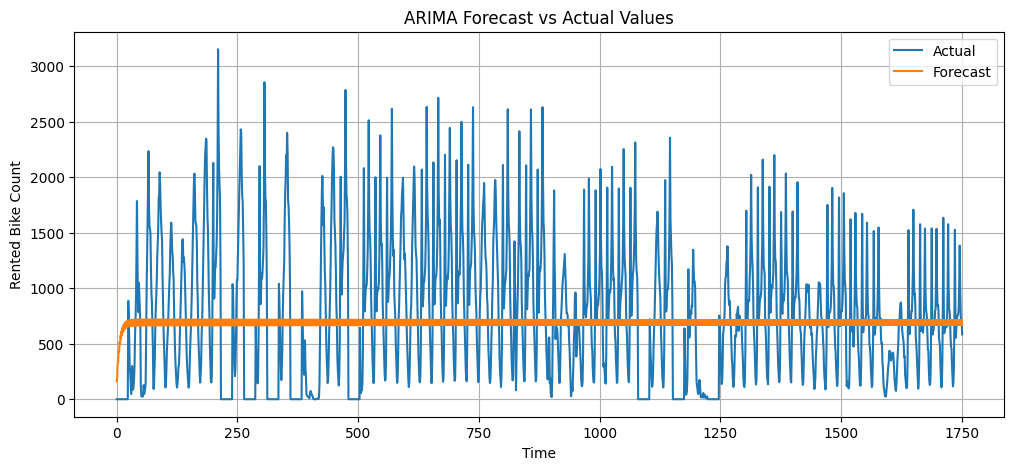

In [50]:
plt.figure(figsize=(12, 5))

plt.plot(test.values, label="Actual")
plt.plot(forecast.values, label="Forecast")

plt.title("ARIMA Forecast vs Actual Values")
plt.xlabel("Time")
plt.ylabel("Rented Bike Count")
plt.legend()
plt.grid(True)

plt.show()

The graph above shows a comparison of the ARIMA 2,0,2 model’s forecast with actual demand for bicycle hire. The model followed the general trend, but the forecast was much smoother than the actual data. It managed to capture some of the changes in demand over time, but did not reflect all the sharp peaks or sudden drops that can be seen in the actual figures. This suggests that, whilst the model is able to represent the general trend in demand for bike hire, it has some difficulty in capturing the smaller, more sudden changes that occur from one hour to the next.

In [51]:
sarima_forecast = sarima_fit.forecast(steps=len(test))

print("SARIMAX Forecast observations:", len(sarima_forecast))

SARIMAX Forecast observations: 1752


In [52]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

sarima_mae = mean_absolute_error(test, sarima_forecast)
sarima_rmse = np.sqrt(mean_squared_error(test, sarima_forecast))

print("SARIMAX MAE:", sarima_mae)
print("SARIMAX RMSE:", sarima_rmse)

SARIMAX MAE: 498.55738984102214
SARIMAX RMSE: 608.3338844065854


I also used the SARIMAX(2,0,2)(1,0,0,24) model to forecast the same 1,752 observations in the test dataset. The model achieved a MAE of 498.557 and an RMSE of 608.334. The results compare the forecasting performance with that of the ARIMA model and examine whether the inclusion of the seasonal component made a difference to the forecasts.

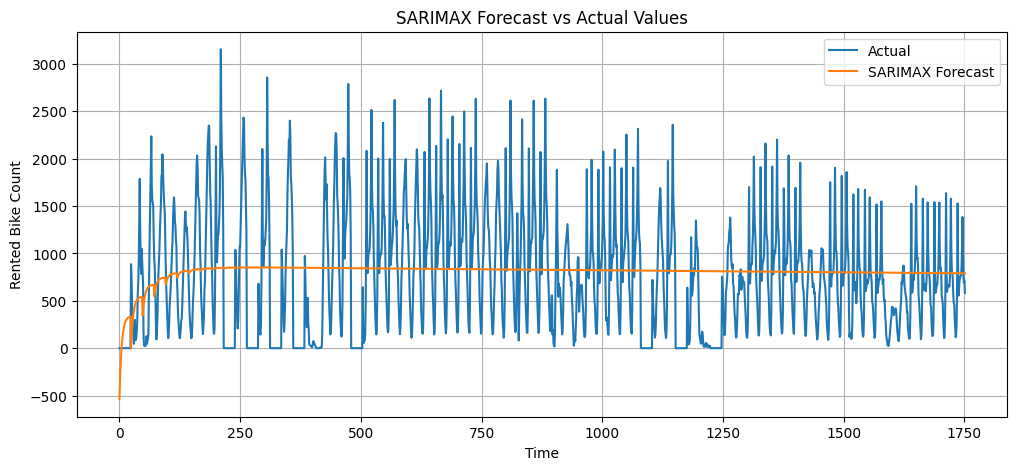

In [53]:
plt.figure(figsize=(12, 5))

plt.plot(test.values, label="Actual")
plt.plot(sarima_forecast.values, label="SARIMAX Forecast")

plt.title("SARIMAX Forecast vs Actual Values")
plt.xlabel("Time")
plt.ylabel("Rented Bike Count")
plt.legend()
plt.grid(True)

plt.show()

On examining the graph above, the SARIMAX forecast showed that the predicted figures were still lower than the actual demand for bike hire. The seasonal component was included to account for possible daily patterns, but the model still struggled to capture some of the sharp peaks and sudden drops in the graph. This shows that, whilst the inclusion of seasonality helped to represent changes in demand over time, it did not capture all the short-term fluctuations in the hourly hire data.

In [54]:
arima_model = ARIMA(
    train,
    order=(2, 0, 2)
)

arima_fit = arima_model.fit(
    method_kwargs={"maxiter":200}
)

print(arima_fit.mle_retvals)

C:\Users\JHENI\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
C:\Users\JHENI\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
C:\Users\JHENI\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
C:\Users\JHENI\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\JHENI\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA paramete

{'fopt': np.float64(6.951635798882137), 'gopt': array([ 1.59516845e-07, -1.23334232e-05,  1.39944056e-05,  7.52722329e-06,
       -3.90558696e-06, -1.29756650e-05]), 'fcalls': 371, 'warnflag': 0, 'converged': True, 'iterations': 46}


In [55]:
forecast = arima_fit.forecast(steps=len(test))

print("Forecasted observations:", len(forecast))

Forecasted observations: 1752


In [56]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))

print("MAE:", mae)
print("RSME:", rmse)

MAE: 499.5281983288486
RSME: 614.6477254449092


The ARIMA 2,0,2 model was fitted using the training data and used to generate forecasts for the 1,752 observations in the testing period.
The model achieved MAE of 499.528 and a RMSE of 614.648. The MAE represents the average absolute difference between the predicted and actual rental counts, while RMSE gives greater weight to larger forecasting erros.
These results provide the quantitative evaluation of the ARIMA model and allow its forecasting performance to be compared directly with the SARIMAX model.

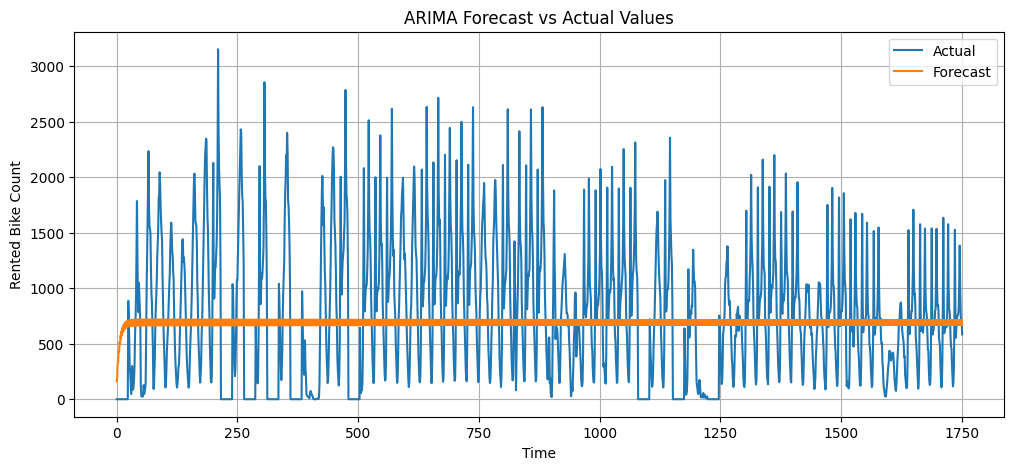

In [57]:
plt.figure(figsize=(12, 5))

plt.plot(test.values, label="Actual")
plt.plot(forecast.values, label="Forecast")

plt.title("ARIMA Forecast vs Actual Values")
plt.xlabel("Time")
plt.ylabel("Rented Bike Count")
plt.legend()
plt.grid(True)

plt.show()

The graph above for the ARIMA model shows that the forecast is noticeably smoother that the actual demand for biki hire. Although the model tracks the general trend of the time series, it does not fully capture several sharp peaks and sudden drops. This may suggest that the ARIMA model captures part of the time structure, but has limited ability to represent rapid, short term changes in demand for hourly bike hire.

## ARIMA and SARIMAX comparison

To compare the forecasting results, I looked at the AIC, MAE and RMSE values for both models. The results are presented below
Model

ARIMA(2,0,2) : (AIC:97,446.127), (MAE:499.528), (RMSE:614.648)
SARIMAX(2,0,2) (1,0,0,24): (AIC: 94,482.136), (498.557), (608.334)

Looking at the results, I noticed that SARIMAX had a lower AIC than ARIMA, decreasing from 97,446.127 to 94,482.136. The forecasting erros were also slightly lower with SARIMAX. The MAE decreased from 499.528 to 498.557, while the RMSE went down from 614.648 to 608.334.
The lower AIC suggests that SARIMAX provided a better balance between model fit and complexity compared with ARIMA. Also, since both the MAE and RMSE were lower, SARIMAX made slightly more accurate predictions when tested against observations that were not used to fit the models.
However, when comparing the error values, I could see that the improvement in MAE was quite small, while the reduction in RMSE was more notiable. Based on these results, SARIMAX performed better overall than ARIMA in this comparison, but the difference was not very large, so it is important not to overstate the improvement.
I also looked at the forecast graphs to understand how the predictions compared with the actual bike rental demand. Both models produced smoother predictions than the actual data and struggled to capture some of the sharp peaks and sudden drops. This suggests that adding the seasonal component helped improve the forecasts, but it did not capture all the changes in hourly bike rental demand.

## Strengths and Limitations of the Models

The data were divided into training and sets in chronological order. The aim was to forecast future demand for bike here using historical data. This approach made it possible to evaluate the models using observations that had not been included during training. Another useful aspect of the analysis was the comparison between the non-seasonal ARIMA model and the seasonal SARIMAX model. This helped to investigate whether assing a daily seasonal component could improve the forecasts.
In the analyses above, different methods were also used to guide model selection. Stationarity was tested using the ADF test. Next, ACF and PACF plots were used to understand the temporal relationships in the data. Different ARIMA specifications were also compared, using the AIC to select the model with the best fit from among the alternatives tested. 
However, it was observed that both models struggled to capture the short-term fluctuations in demand for bicycle hire. The actual data contained sharp peaks and sudden drops that were not fully reflected in the forecasts. Although SARIMAX produced better numerical results than ARIMA, the improvement in forecast accuracy was relatively small. This suggests that the inclusion of the daily seasonal component helped, but was not sufficient to capture all the variations in demand.
Another limitation is that both models focused on the ‘Number of bicycles rented’ time series, without directly utilising the other explanatory variables available in the dataset. For example, temperature, humidity, precipitation, snowfall, public holidays and working days could also influence demand for bicycle hire. Including these variables in a suitable forecasting model could help explain changes that cannot be fully understood from historical rental figures alone.
I also took into account the warnings generated during model estimation when interpreting the results. For the ARIMA model, the warnings related to the initial parameter values and the inferred hourly frequency of the data. For the SARIMAX model, the output included a warning that the covariance matrix was singular or nearly singular, meaning that the estimated standard errors of the coefficients could be unstable. These warnings represent important limitations that must be acknowledged, although both models converged successfully and their forecasting performance was assessed using out-of-sample metrics.

## Conclusion

During the time series analysis, the Number of bicycles hired varied considerably over time. The analysis also showed that there was a relationship between observations at different points in time and a possible daily seasonal pattern in the data.
The ADF test returned a p-value of 9.91478 × 10⁻¹⁰, which supported the use of d = 0 in the ARIMA model. Upon examining the ACF and PACF plots,  it was possible to observe strong autocorrelation in the early lags and a pattern around lag 24. As the data were recorded hourly, this suggested that there might be a daily pattern in the demand for bicycle hire.
After testing different combinations of "p" and "q" and comparing their AIC values, I selected ARIMA(2,0,2) as the best non-seasonal model amongst those tested. It achieved an AIC of 97,446.127. I then tested the seasonal model SARIMAX(2,0,2)(1,0,0,24) to check whether including a daily seasonal component could improve the forecasts.
When comparing the results, SARIMAX produced lower values for all three measures: AIC, MAE and RMSE. Its MAE was 498.557, compared with 499.528 for ARIMA, whilst its RMSE was 608.334, compared with 614.648. Based on these results, SARIMAX performed slightly better than ARIMA in forecasting the observations in the test dataset.
We can conclude that, when analysing the forecast visualisations, both models still struggled to capture the sharp peaks and sudden drops in demand for bike hire. This means that, although the inclusion of the daily seasonal component improved the results, it did not capture all the variations in demand. Overall, I found that SARIMAX was the better-performing model of the two tested, but the inclusion of other variables, such as temperature, humidity, precipitation and public holidays, could help explain some of the variations that were not captured by the historical rental data alone.

## Reference

Eren, E. and Uz, V.E. (2020) ‘A review on bike-sharing: The factors affecting bike-sharing demand’, Sustainable Cities and Society, 54, 101882. Available at: https://doi.org/10.1016/j.scs.2019.101882 (Accessed: 15 October 2026). ScienceDirect

UCI Machine Learning Repository (2020) Seoul Bike Sharing Demand [Dataset]. Available at: https://doi.org/10.24432/C5F62R (Accessed: 15 October 2026).

Scikit-learn Developers (2026) Scikit-learn: Machine Learning in Python. Available at: https://scikit-learn.org/ (Accessed: 18 October 2026).

Iqbal, M. (2026) ARIMA and SARIMA Time Series Models. Week 7 lecture material, HDIP in Data Analytics for Business, CCT College Dublin.

OpenAI (2026) ChatGPT. Available at: https://chatgpt.com/ (Accessed: 18 October 2026).

Statsmodels Developers (2026) Statsmodels: Statistical Models and Tests. Available at: https://www.statsmodels.org/ (Accessed: 22 October 2026).